In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q transformers timm

In [3]:
import os
import torch
import numpy as np

from PIL import Image
from tqdm import tqdm

from transformers import AutoImageProcessor
from transformers import AutoModel

from torch.utils.data import Dataset
from torch.utils.data import DataLoader

In [4]:
DATASET_PATH = "/content/drive/MyDrive/Coffee_DINO"

In [5]:
CLASS_NAMES = {
    "cut":0,
    "good":1,
    "husk":2,
    "immature":3,
    "parchment":4,
    "partial-black":5,
    "shell":6
}

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [7]:
processor = AutoImageProcessor.from_pretrained(
    "facebook/dinov2-base"
)

dinov2 = AutoModel.from_pretrained(
    "facebook/dinov2-base"
)

dinov2.to(device)

dinov2.eval()

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Dinov2Model(
  (embeddings): Dinov2Embeddings(
    (patch_embeddings): Dinov2PatchEmbeddings(
      (projection): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (encoder): Dinov2Encoder(
    (layer): ModuleList(
      (0-11): 12 x Dinov2Layer(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (attention): Dinov2Attention(
          (attention): Dinov2SelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
          )
          (output): Dinov2SelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
        )
        (layer_scale1): Dinov2LayerScale()
        (drop_path): Identity()
        (norm2): LayerNorm((768,), eps=1e-06,

In [8]:
DATASET_PATH = "/content/drive/MyDrive/Coffee_DINO"

CLASS_NAMES = {
    "cut":0,
    "good":1,
    "husk":2,
    "immature":3,
    "parchment":4,
    "partial-black":5,
    "shell":6
}

In [18]:
class CoffeeDataset(Dataset):

    def __init__(self, root_dir):

        self.samples = []

        for class_name, label in CLASS_NAMES.items():

            class_folder = os.path.join(root_dir, class_name)

            if not os.path.exists(class_folder):
                continue

            for image_name in os.listdir(class_folder):

                if image_name.endswith((".png", ".jpg", ".jpeg")):

                    self.samples.append(
                        (
                            os.path.join(class_folder, image_name),
                            label
                        )
                    )

    def __len__(self):

        return len(self.samples)

    def __getitem__(self, idx):

        image_path, label = self.samples[idx]

        image = Image.open(image_path).convert("RGB")

        return image, label



def collate_fn(batch):

    images = [item[0] for item in batch]

    labels = torch.tensor([item[1] for item in batch])

    return images, labels

In [19]:
train_dataset = CoffeeDataset(
    os.path.join(DATASET_PATH,"train")
)

print(len(train_dataset))

4368


0


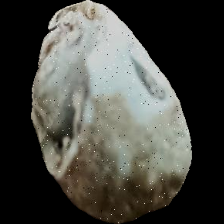

In [20]:
image,label = train_dataset[0]

print(label)

image

In [24]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

In [25]:
valid_loader = DataLoader(
    CoffeeDataset(os.path.join(DATASET_PATH, "valid")),
    batch_size=32,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)
test_loader = DataLoader(
    CoffeeDataset(os.path.join(DATASET_PATH, "test")),
    batch_size=32,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

In [26]:
images, labels = next(iter(train_loader))

print(type(images))
print(type(images[0]))
print(labels.shape)

<class 'list'>
<class 'PIL.Image.Image'>
torch.Size([32])


In [27]:
def extract_features(loader):

    features = []
    labels = []

    for images, batch_labels in tqdm(loader):

        inputs = processor(
            images=images,
            return_tensors="pt"
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = dinov2(**inputs)

        batch_features = outputs.last_hidden_state[:, 0, :]

        features.append(batch_features.cpu())

        labels.extend(batch_labels.numpy())

    features = torch.cat(features).numpy()
    labels = np.array(labels)

    return features, labels

In [28]:
train_features, train_labels = extract_features(train_loader)

valid_features, valid_labels = extract_features(valid_loader)

test_features, test_labels = extract_features(test_loader)

 94%|█████████▍| 129/137 [09:54<00:45,  5.70s/it]Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e0f207d9440>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
100%|██████████| 7/7 [00:41<00:00,  5.89s/it]


In [29]:
import os

SAVE_PATH = "/content/drive/MyDrive/DINO_Features"

os.makedirs(SAVE_PATH, exist_ok=True)

In [30]:
np.savez_compressed(
    os.path.join(SAVE_PATH, "train_data.npz"),
    features=train_features,
    labels=train_labels
)

In [31]:
np.savez_compressed(
    os.path.join(SAVE_PATH, "valid_data.npz"),
    features=valid_features,
    labels=valid_labels
)

In [32]:
np.savez_compressed(
    os.path.join(SAVE_PATH, "test_data.npz"),
    features=test_features,
    labels=test_labels
)